# Random Forests for Predicting Numbers: Estimating Glucose

In the decision tree examples, our models answered **category** questions: *Does this patient have diabetes?* *Which species is this flower?* That kind of problem is called **classification**.

Decision trees and random forests can also predict **numbers**. That kind of problem is called **regression**. In this example we try to estimate a patient's **blood glucose level** from her other measurements (age, BMI, insulin, and so on), without using the glucose test itself.

| | Classification | Regression |
|---|---|---|
| What we predict | a category (yes/no, species) | a number (glucose level) |
| What a tree leaf says | "the most common class here" | "the **average** value here" |
| How a forest combines its trees | **vote** | **average** |
| How we measure success | accuracy, confusion matrix | average error, R² |

**Roadmap**

| Part | What we do |
|---|---|
| 0 | Look at the data, and set a baseline to beat |
| 1 | See how a single **regression tree** works |
| 2 | Build a random forest for regression by hand, step by step |
| 3 | Use scikit-learn's `RandomForestRegressor` (the original example) |
| 4 | Compare the models and discuss what the results mean |

> **How to use this notebook:** run the cells from top to bottom (Shift + Enter). Read the text above each code cell before you run it, and try to predict what will happen.

## Part 0: The Data

This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

https://www.kaggle.com/uciml/pima-indians-diabetes-database/version/1#

**Each row is one patient.** The columns are:

| Column | What it means |
|---|---|
| `Pregnancies` | Number of times pregnant |
| `Glucose` | Blood sugar level 2 hours after drinking a sugary drink (glucose tolerance test). **This is what we will predict.** |
| `BloodPressure` | Diastolic blood pressure (mm Hg) |
| `SkinThickness` | Thickness of a skin fold on the back of the arm (mm), a rough measure of body fat |
| `Insulin` | Insulin level in the blood 2 hours after the sugary drink |
| `BMI` | Body mass index: weight (kg) / height (m)² |
| `DiabetesPedigreeFunction` | A score summarizing how much diabetes runs in the patient's family |
| `Age` | Age in years |
| `Outcome` | 1 = has diabetes, 0 = does not (we will **not** use this column here) |

In [13]:
# read the data into a Pandas DataFrame
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('pima_indians_diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### A data-quality warning

In this dataset, a value of **0** in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, or `BMI` really means *"this measurement is missing"*. Nobody has a blood glucose level of 0! Let's count them.

In [14]:
cols_with_fake_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
(df[cols_with_fake_zeros] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

A few patients even have a glucose value of 0, and `Insulin` is missing (0) for about half of the patients. To stay close to the original example, we will keep the data as it is. Keep this in mind when we look at the results; cleaning the data is one of the "Try it yourself" exercises at the end.

### What are we trying to predict?

Let's look at the glucose values, our **target**.

count    768.0
mean     120.9
std       32.0
min        0.0
25%       99.0
50%      117.0
75%      140.2
max      199.0
Name: Glucose, dtype: float64


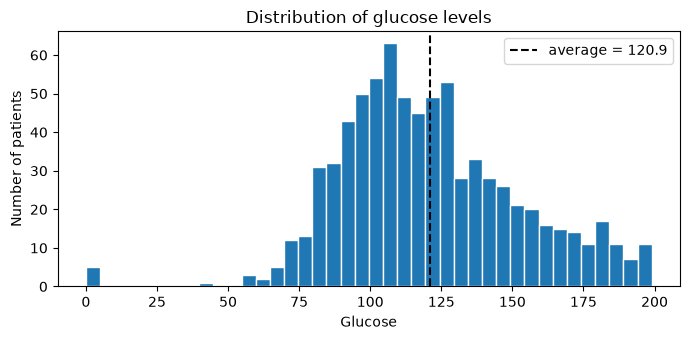

In [15]:
print(df['Glucose'].describe().round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df['Glucose'], bins=40, color='tab:blue', edgecolor='white')
ax.axvline(df['Glucose'].mean(), color='black', linestyle='--',
           label=f"average = {df['Glucose'].mean():.1f}")
ax.set_xlabel('Glucose')
ax.set_ylabel('Number of patients')
ax.set_title('Distribution of glucose levels')
ax.legend()
plt.tight_layout()
plt.show()

Most patients have glucose levels between about 80 and 160, and a handful sit at the "missing" value of 0 on the far left.

### How strongly is each feature related to glucose?

Each panel below plots one feature against glucose; each dot is a patient. The number **r** in each title is the **correlation**, a number between -1 and 1 that measures how closely the dots follow a straight-line trend:

* r near **0**: no clear straight-line relationship,
* r near **1** (or **-1**): a strong upward (or downward) trend.

**Before running the next cell, guess:** will it be easy or hard to predict glucose from these features?

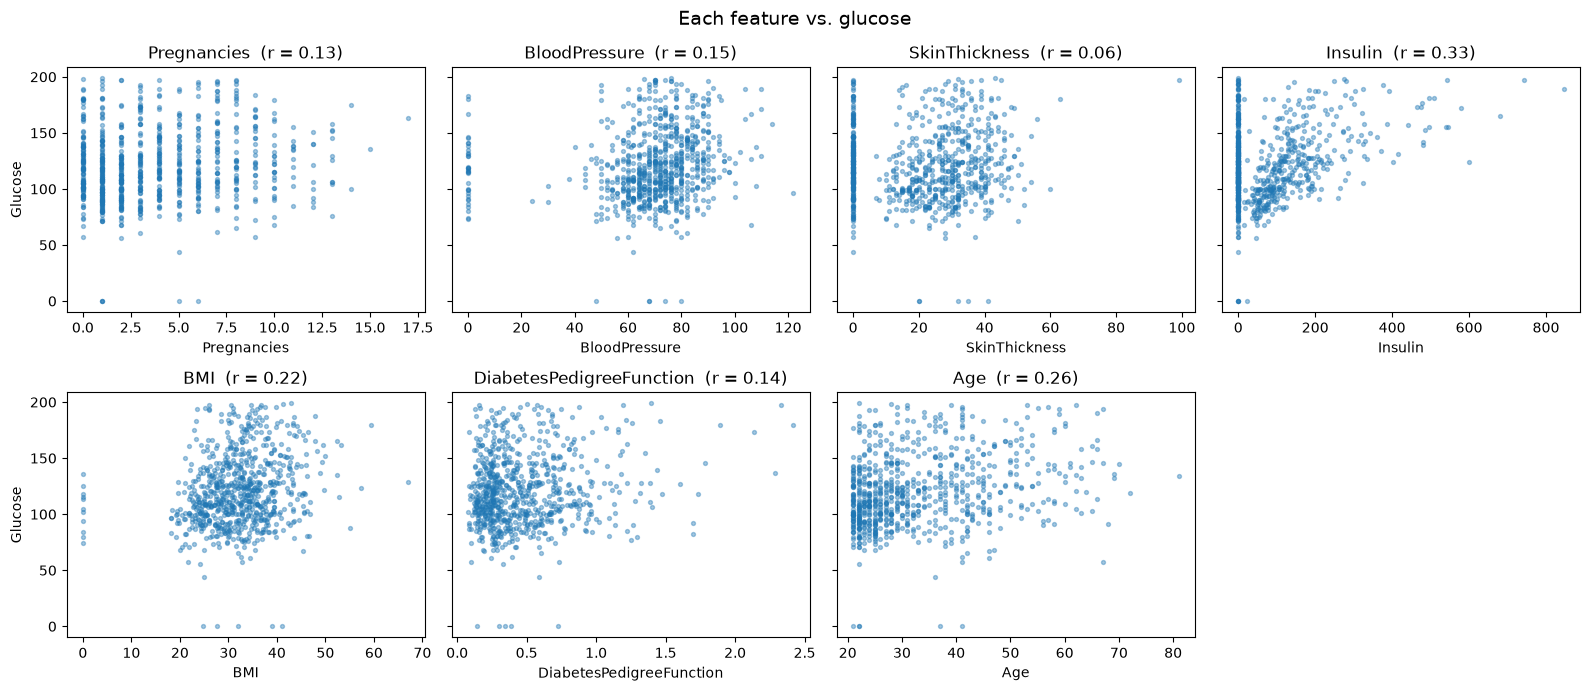

In [16]:
feature_cols = ['Pregnancies', 'BloodPressure', 'SkinThickness', 'Insulin',
                'BMI', 'DiabetesPedigreeFunction', 'Age']

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, col in zip(axes.ravel(), feature_cols):
    r = df[col].corr(df['Glucose'])
    ax.scatter(df[col], df['Glucose'], s=8, alpha=0.4, color='tab:blue')
    ax.set_title(f'{col}  (r = {r:.2f})')
    ax.set_xlabel(col)
axes[0, 0].set_ylabel('Glucose')
axes[1, 0].set_ylabel('Glucose')
axes[1, 3].axis('off')
fig.suptitle('Each feature vs. glucose', fontsize=14)
plt.tight_layout()
plt.show()

The clouds of dots are mostly shapeless and all of the correlations are fairly small. No single feature predicts glucose well. This is going to be a **hard** prediction problem, and that's okay: part of learning data science is learning to recognize when a problem is hard, and to measure honestly how well a model does.

### Define X and y

* `X`: the **features**, the seven measurements we are allowed to use.
* `y`: the **target**, the glucose level we want to predict.

Notice that `Glucose` is **not** in `X` (that would be cheating), and neither is `Outcome`.

In [17]:
# define X and y
X = df[['Pregnancies', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']]

y = df['Glucose']

### Split into training and testing sets

As before, the model learns from the **training set** (80% of the patients) and is graded on the **testing set** (20%), patients it has never seen. `random_state=1` makes the split the same every time.

In [18]:
# split X and y into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=1)

print("Training patients:", len(X_train))
print("Testing patients: ", len(X_test))

Training patients: 614
Testing patients:  154


### How do we measure the quality of a number prediction?

With classification, a prediction was simply right or wrong. With numbers, a prediction is almost never *exactly* right, so we measure **how far off** it is. The difference between the actual value and the prediction is called the **error** (or **residual**).

We will use two measures:

**1. Mean absolute error (MAE):** the average size of the error, ignoring whether we guessed too high or too low.

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |\,\text{actual}_i - \text{predicted}_i\,|$$

An MAE of 20 means "on average, our guess is off by 20 glucose units." Smaller is better.

**2. R² (R-squared):** compares the model to the simplest possible strategy, **always guessing the average**:

$$R^2 = 1 - \frac{\text{sum of squared errors of the model}}{\text{sum of squared errors when always guessing the average}}$$

* R² = **1**: perfect predictions.
* R² = **0**: no better than always guessing the average.
* R² **below 0**: *worse* than always guessing the average!

### The baseline: always guess the average

Before building any model, let's see how well the "always guess the average" strategy does. Any model worth using has to beat it. We compute the average from the **training** patients only, because we are not allowed to peek at the test set.

In [19]:
from sklearn import metrics

baseline_guess = y_train.mean()
baseline_pred = np.full(len(y_test), baseline_guess)

baseline_mae = metrics.mean_absolute_error(y_test, baseline_pred)
baseline_r2 = metrics.r2_score(y_test, baseline_pred)
print(f"Baseline: always guess {baseline_guess:.1f}")
print(f"  MAE = {baseline_mae:.1f}")
print(f"  R²  = {baseline_r2:.3f}   (close to 0, as expected)")

Baseline: always guess 121.3
  MAE = 25.6
  R²  = -0.003   (close to 0, as expected)



## Part 1: How a Regression Tree Works

A **regression tree** is a flowchart of yes/no questions, exactly like the decision trees we have used for classification. The differences are:

1. **What a leaf predicts:** each leaf predicts the **average glucose** of the training patients that ended up in it.
2. **How questions are chosen:** instead of Gini impurity, the tree measures how **spread out** the glucose values in a group are, using the **mean squared error**:

$$\text{MSE of a group} = \frac{1}{n}\sum_{i=1}^{n} (\text{glucose}_i - \text{group average})^2$$

If everyone in a group has nearly the same glucose, the MSE is small. The tree tries every feature and cut-off, and picks the question whose two groups have the smallest (weighted) MSE. In other words, it looks for the question that sorts patients into groups with **similar glucose levels**.

### A small tree to look at

Let's grow a tree with only 2 levels of questions (`max_depth=2`) so it is easy to read. In each box:

* **squared_error** is the MSE of the glucose values in the box,
* **samples** is the number of training patients in the box,
* **value** is their **average glucose**. For a leaf, this is the prediction.

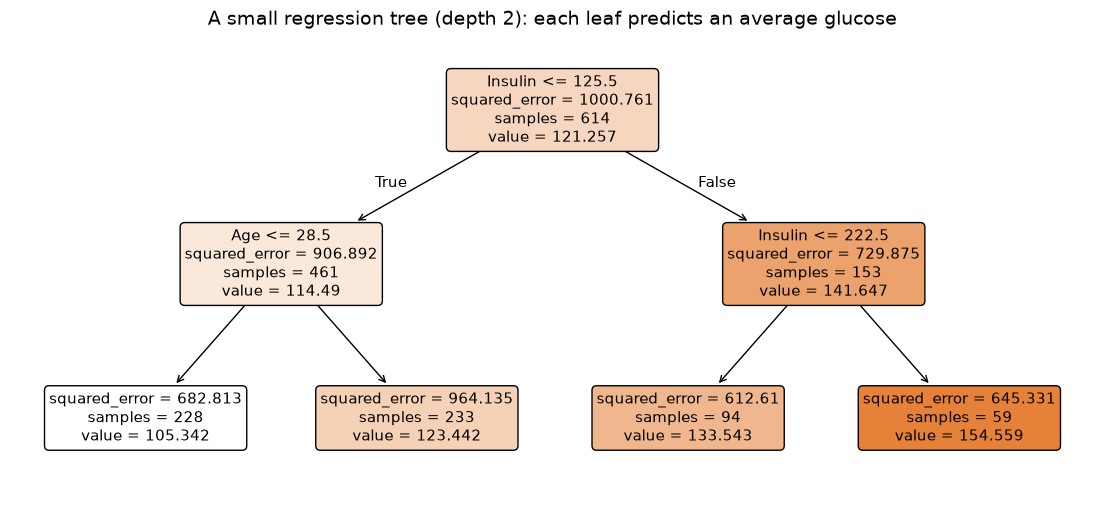

In [20]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

small_tree = DecisionTreeRegressor(max_depth=2, random_state=1)
small_tree.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(small_tree, feature_names=X.columns, filled=True, rounded=True, fontsize=11, ax=ax)
ax.set_title('A small regression tree (depth 2): each leaf predicts an average glucose', fontsize=14)
plt.show()

With depth 2, the tree has 4 leaves, so it can only make **4 different predictions**: every test patient gets one of those 4 averages.

If you see a leaf with only one or two patients and a `value` close to 0, the tree has found some of the patients whose glucose was recorded as 0 (missing). Isolating them reduces the squared error a lot, because their values are so far from everyone else's. This is one way that messy data can mislead a model.

### Checking the first question by hand

Let's verify the root question ourselves: split the training patients by the root question, and compare the MSE before and after the split.

In [21]:
root_feature = X.columns[small_tree.tree_.feature[0]]
root_threshold = small_tree.tree_.threshold[0]
print(f"Root question: Is {root_feature} <= {root_threshold:.1f}?\n")

def mse_of_group(values):
    return ((values - values.mean()) ** 2).mean()

yes_group = y_train[X_train[root_feature] <= root_threshold]
no_group = y_train[X_train[root_feature] > root_threshold]
mse_before = mse_of_group(y_train)
mse_after = (len(yes_group) * mse_of_group(yes_group) + len(no_group) * mse_of_group(no_group)) / len(y_train)

print(f"All training patients: {len(y_train)} patients, average glucose {y_train.mean():.1f}, MSE {mse_before:.1f}")
print(f"'Yes' group:           {len(yes_group)} patients, average glucose {yes_group.mean():.1f}, MSE {mse_of_group(yes_group):.1f}")
print(f"'No' group:            {len(no_group)} patients, average glucose {no_group.mean():.1f}, MSE {mse_of_group(no_group):.1f}")
print(f"Weighted MSE after the split: {mse_after:.1f}  (lower than {mse_before:.1f}, so the groups are a bit more alike)")

Root question: Is Insulin <= 125.5?

All training patients: 614 patients, average glucose 121.3, MSE 1000.8
'Yes' group:           461 patients, average glucose 114.5, MSE 906.9
'No' group:            153 patients, average glucose 141.6, MSE 729.9
Weighted MSE after the split: 862.8  (lower than 1000.8, so the groups are a bit more alike)


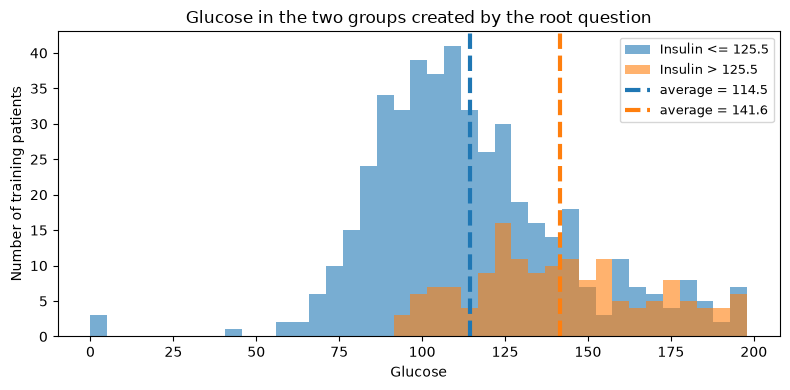

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(y_train.min(), y_train.max(), 40)
ax.hist(yes_group, bins=bins, alpha=0.6, color='tab:blue', label=f'{root_feature} <= {root_threshold:.1f}')
ax.hist(no_group, bins=bins, alpha=0.6, color='tab:orange', label=f'{root_feature} > {root_threshold:.1f}')
ax.axvline(yes_group.mean(), color='tab:blue', linewidth=3, linestyle='--', label=f'average = {yes_group.mean():.1f}')
ax.axvline(no_group.mean(), color='tab:orange', linewidth=3, linestyle='--', label=f'average = {no_group.mean():.1f}')
ax.set_xlabel('Glucose')
ax.set_ylabel('Number of training patients')
ax.set_title('Glucose in the two groups created by the root question')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

The two groups have different averages, but their glucose values still **overlap a lot**. The question helps, but only a little. This is the same message as the scatter plots: the features carry only weak information about glucose.

### A regression tree makes a "staircase"

To *see* what a regression tree does, let's use just **one** feature, `Age`, so we can draw the prediction as a line. Because each leaf predicts a single number, the prediction is **flat** inside each leaf's range of ages and **jumps** at each cut-off. The result looks like a staircase.

We draw trees of increasing depth. Watch what happens to the staircase as the tree is allowed to ask more questions.

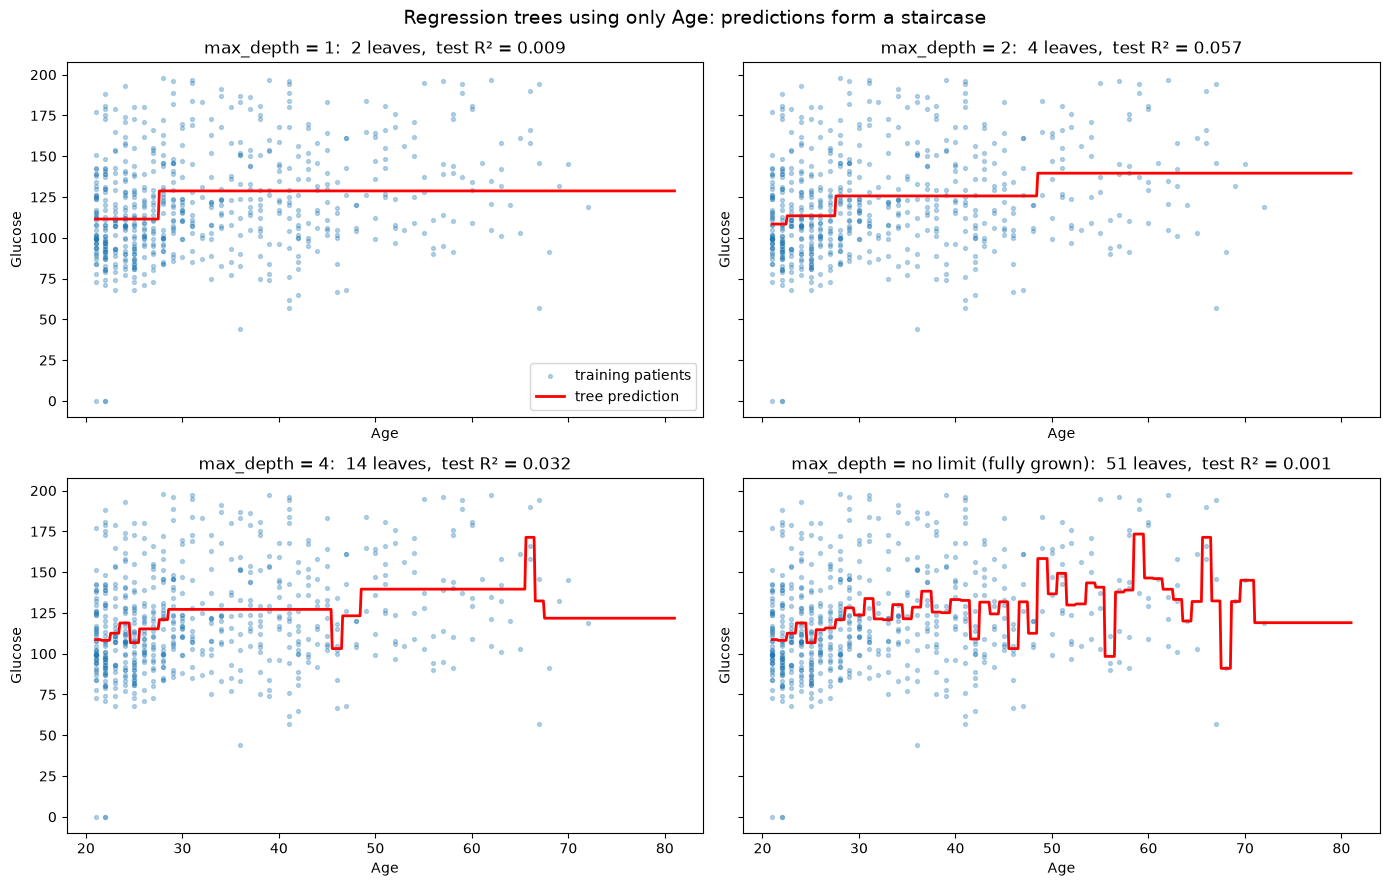

In [23]:
age_grid = pd.DataFrame({'Age': np.linspace(X['Age'].min(), X['Age'].max(), 500)})

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, depth in zip(axes.ravel(), [1, 2, 4, None]):
    age_tree = DecisionTreeRegressor(max_depth=depth, random_state=1).fit(X_train[['Age']], y_train)
    ax.scatter(X_train['Age'], y_train, s=8, alpha=0.3, color='tab:blue', label='training patients')
    ax.plot(age_grid['Age'], age_tree.predict(age_grid), color='red', linewidth=2, label='tree prediction')
    test_r2 = age_tree.score(X_test[['Age']], y_test)
    label = 'no limit (fully grown)' if depth is None else depth
    ax.set_title(f'max_depth = {label}:  {age_tree.get_n_leaves()} leaves,  test R² = {test_r2:.3f}')
    ax.set_xlabel('Age')
    ax.set_ylabel('Glucose')
axes[0, 0].legend(loc='lower right')
fig.suptitle('Regression trees using only Age: predictions form a staircase', fontsize=14)
plt.tight_layout()
plt.show()

* With **depth 1**, the tree asks one question, so the staircase has a single step.
* With more depth, the staircase gets more steps and follows the general upward trend better.
* Sudden dips toward very low values are the tree chasing the few patients whose glucose was recorded as 0.
* The **fully grown** tree jumps up and down wildly. It has a leaf for almost every age in the training data, so it is chasing individual patients instead of the overall trend. This is **overfitting**, and the test R² gets worse (it may even be negative, meaning worse than guessing the average).

### Overfitting with all the features

The same thing happens when we use all seven features. Below we grow trees of increasing depth and measure R² on the training set and on the test set.

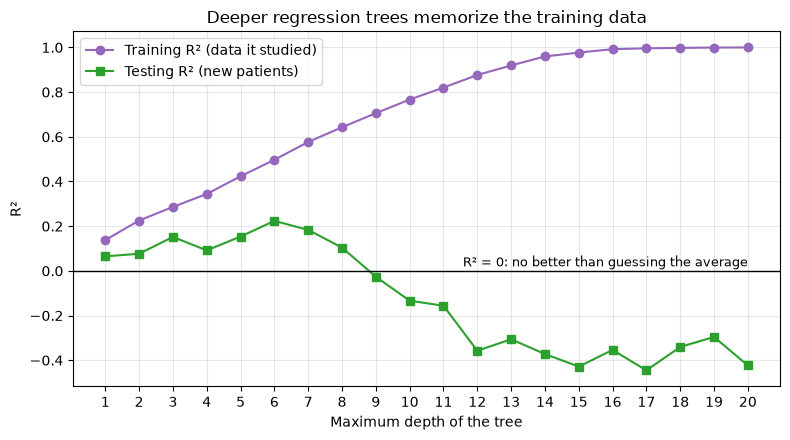

In [24]:
depths = range(1, 21)
train_r2, test_r2 = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=1).fit(X_train, y_train)
    train_r2.append(t.score(X_train, y_train))   # .score() returns R² for regression models
    test_r2.append(t.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, train_r2, 'o-', color='tab:purple', label='Training R² (data it studied)')
ax.plot(depths, test_r2, 's-', color='tab:green', label='Testing R² (new patients)')
ax.axhline(0, color='black', linewidth=1)
ax.text(20, 0.02, 'R² = 0: no better than guessing the average', ha='right', fontsize=9)
ax.set_xlabel('Maximum depth of the tree')
ax.set_ylabel('R²')
ax.set_title('Deeper regression trees memorize the training data')
ax.set_xticks(list(depths))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

As the tree gets deeper, the training R² climbs toward 1 (perfect), because the tree memorizes every training patient. The test R² does not follow; it drops, often below 0. A single deep tree is a poor predictor here.

Let's keep one single tree with `max_depth=10`, the same depth limit the original example uses for its forest, so we can compare it with the forest later.

In [25]:
single_tree = DecisionTreeRegressor(max_depth=10, random_state=1).fit(X_train, y_train)
single_tree_pred = single_tree.predict(X_test)
print(f"Single tree (max_depth=10): training R² = {single_tree.score(X_train, y_train):.3f}, "
      f"test R² = {metrics.r2_score(y_test, single_tree_pred):.3f}, "
      f"test MAE = {metrics.mean_absolute_error(y_test, single_tree_pred):.1f}")

Single tree (max_depth=10): training R² = 0.767, test R² = -0.133, test MAE = 26.2



## Part 2: A Random Forest for Regression, Step by Step

A random forest for regression follows almost the same recipe as for classification. The only real change is in the last step: instead of **voting**, the trees' predictions are **averaged**.

```
                       Training data (614 patients)
                                    |
        +------------------+--------+---------+------------------+
        |                  |                  |                  |
 STEP 1: Bootstrap  Bootstrap sample 2  Bootstrap sample 3 ...  sample N
     sample 1              |                  |                  |
        |                  |                  |                  |
 STEP 2 & 3: grow a regression tree on each sample
     Tree 1             Tree 2             Tree 3      ...    Tree N
        |                  |                  |                  |
   predicts 112       predicts 131       predicts 104   ...  predicts 120
        +------------------+--------+---------+------------------+
                                    |
              STEP 4: AVERAGE the predictions = final prediction
```

### Why averaging helps

In 1906, about 800 visitors at an English country fair guessed the weight of an ox. Individual guesses were far off in both directions, but the **average** guess was within about 1% of the true weight. Errors that point in different directions cancel out when you average them.

Each deep tree in a forest is like one of those guessers: its predictions are noisy, too high for some patients and too low for others. If the trees' errors are *different*, averaging cancels a lot of the noise.

### Step 1: Bootstrap sampling

Each tree trains on its own **bootstrap sample**: the same number of patients as the training set, drawn **with replacement**. Some patients get picked several times, others are left out (on average about 37% of them). A quick reminder with 10 patients:

In [26]:
rng = np.random.default_rng(42)
patients = np.arange(10)
boot = rng.choice(patients, size=10, replace=True)   # replace=True: a patient can be drawn again
print("Original patients:", patients)
print("Bootstrap sample: ", np.sort(boot))
print("Never picked:     ", sorted(int(p) for p in set(patients) - set(boot)))

Original patients: [0 1 2 3 4 5 6 7 8 9]
Bootstrap sample:  [0 0 0 2 4 4 6 6 7 8]
Never picked:      [1, 3, 5, 9]


### Step 2: Random features at each question (optional for regression)

For classification, scikit-learn's forest only lets each question look at a random handful of features (`max_features='sqrt'`) to make the trees more different.

**For regression, scikit-learn's default is different:** `RandomForestRegressor` uses `max_features=1.0`, meaning *all* the features are considered at every question. So by default, the trees in a regression forest get their variety only from the bootstrap in Step 1. (A forest that uses only bootstrap samples is also called **bagging**.)

Since the original example uses the default, our hand-built forest will too. One of the "Try it yourself" exercises asks you to turn Step 2 back on and see whether it helps.

### Step 3: Grow many trees

We grow 25 regression trees, each on its own bootstrap sample, with the same `max_depth=10` limit as the original example.

In [27]:
n_trees = 25
my_trees = []
rng = np.random.default_rng(0)
n = len(X_train)

for i in range(n_trees):
    # Step 1: bootstrap sample of the training patients
    boot_idx = rng.choice(n, size=n, replace=True)
    X_boot = X_train.iloc[boot_idx]
    y_boot = y_train.iloc[boot_idx]

    # Step 3: grow a regression tree on it (all features allowed, like scikit-learn's default)
    tree = DecisionTreeRegressor(max_depth=10, random_state=i)
    tree.fit(X_boot, y_boot)
    my_trees.append(tree)

print(f"Built {len(my_trees)} trees.")

Built 25 trees.


### Step 4: Average the predictions

Every tree predicts a glucose value for every test patient. The forest's prediction is the **average** of the 25 predictions.

Below, each column is one test patient. The gray dots are the 25 individual trees' predictions, the green diamond is the forest's average, and the red X is the patient's actual glucose.

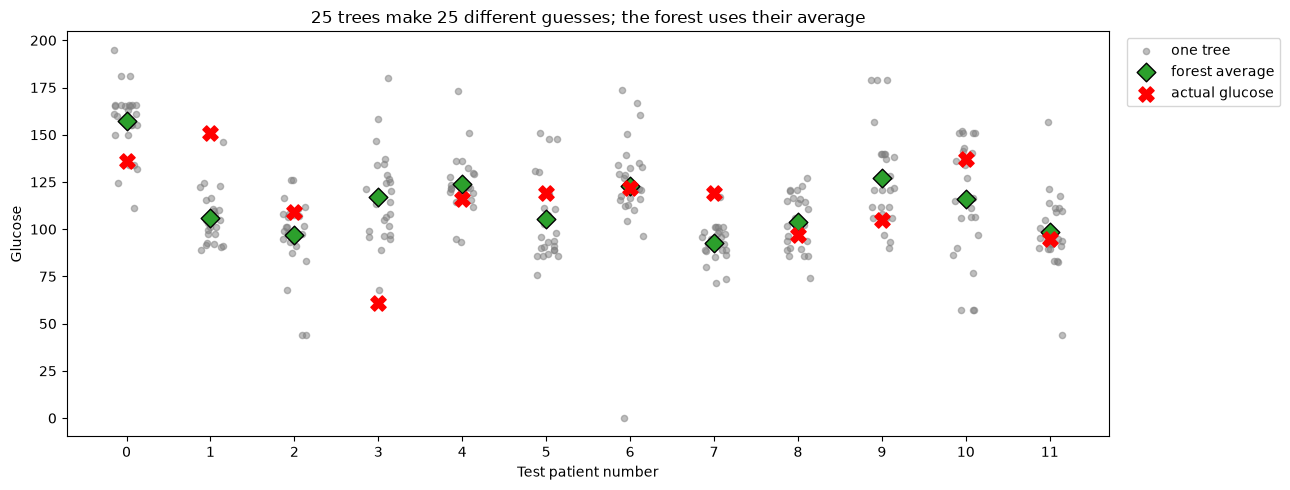

In [28]:
# one row per tree, one column per test patient
all_preds = np.array([t.predict(X_test) for t in my_trees])
my_forest_pred = all_preds.mean(axis=0)      # Step 4: average over the trees

n_show = 12
fig, ax = plt.subplots(figsize=(13, 5))
rng_plot = np.random.default_rng(0)
for p in range(n_show):
    ax.scatter(p + rng_plot.uniform(-0.15, 0.15, n_trees), all_preds[:, p],
               color='tab:gray', alpha=0.5, s=20, label='one tree' if p == 0 else None)
ax.scatter(range(n_show), my_forest_pred[:n_show], color='tab:green', marker='D', s=90,
           edgecolor='k', zorder=3, label='forest average')
ax.scatter(range(n_show), y_test.values[:n_show], color='red', marker='X', s=120,
           zorder=4, label='actual glucose')
ax.set_xticks(range(n_show))
ax.set_xlabel('Test patient number')
ax.set_ylabel('Glucose')
ax.set_title('25 trees make 25 different guesses; the forest uses their average')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

The individual trees **disagree a lot**: for a single patient, their guesses can be spread over a range of 50 or more glucose units. The average sits in the middle of that spread, so it avoids the most extreme guesses. Notice also that the average is still often far from the red X; remember that this is a hard problem.

The same thing as numbers, for the first 5 test patients:

In [29]:
pred_table = pd.DataFrame({
    'lowest tree guess': all_preds.min(axis=0),
    'highest tree guess': all_preds.max(axis=0),
    'forest average': my_forest_pred,
    'actual glucose': y_test.values,
}, index=X_test.index).round(1)
pred_table.head()

,lowest tree guess,highest tree guess,forest average,actual glucose
285,111.0,195.0,157.1,136
101,88.8,146.0,106.0,151
581,44.0,126.3,97.1,109
352,68.0,180.0,117.0,61
726,93.0,173.0,124.1,116


### Does the crowd beat the individuals?

Each gray dot below is the test R² of one of our trees on its own. The green line is the R² of the forest's average. (Remember: R² = 0 means "no better than always guessing the average," shown by the black line.)

Average R² of a single tree:   -0.343
Best single tree:              0.066
Hand-built forest (25 trees):  0.234


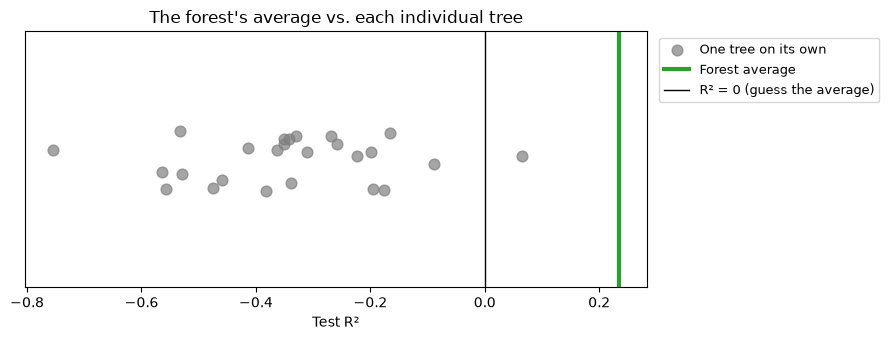

In [30]:
single_r2 = np.array([metrics.r2_score(y_test, p) for p in all_preds])
my_forest_r2 = metrics.r2_score(y_test, my_forest_pred)
print(f"Average R² of a single tree:   {single_r2.mean():.3f}")
print(f"Best single tree:              {single_r2.max():.3f}")
print(f"Hand-built forest (25 trees):  {my_forest_r2:.3f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, n_trees)
ax.scatter(single_r2, jitter, s=60, alpha=0.7, color='tab:gray', label='One tree on its own')
ax.axvline(my_forest_r2, color='tab:green', linewidth=3, label='Forest average')
ax.axvline(0, color='black', linewidth=1, label='R² = 0 (guess the average)')
ax.set_yticks([])
ax.set_ylim(-0.6, 0.6)
ax.set_xlabel('Test R²')
ax.set_title("The forest's average vs. each individual tree")
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()

This is the most important picture in the notebook. You will probably see that individual deep trees are **worse than guessing the average** (R² below 0): they have memorized their bootstrap samples. Yet when we average them, the result is far better than the typical single tree, and usually better than all of them. The noise in each tree's predictions largely cancels out.

### Seeing the smoothing effect

Let's go back to using only `Age`. On the left is one tree with `max_depth=4`; on the right is a forest of 100 trees with the same depth limit. Each tree in the forest is trained on a different bootstrap sample, so each puts its staircase steps in slightly different places.

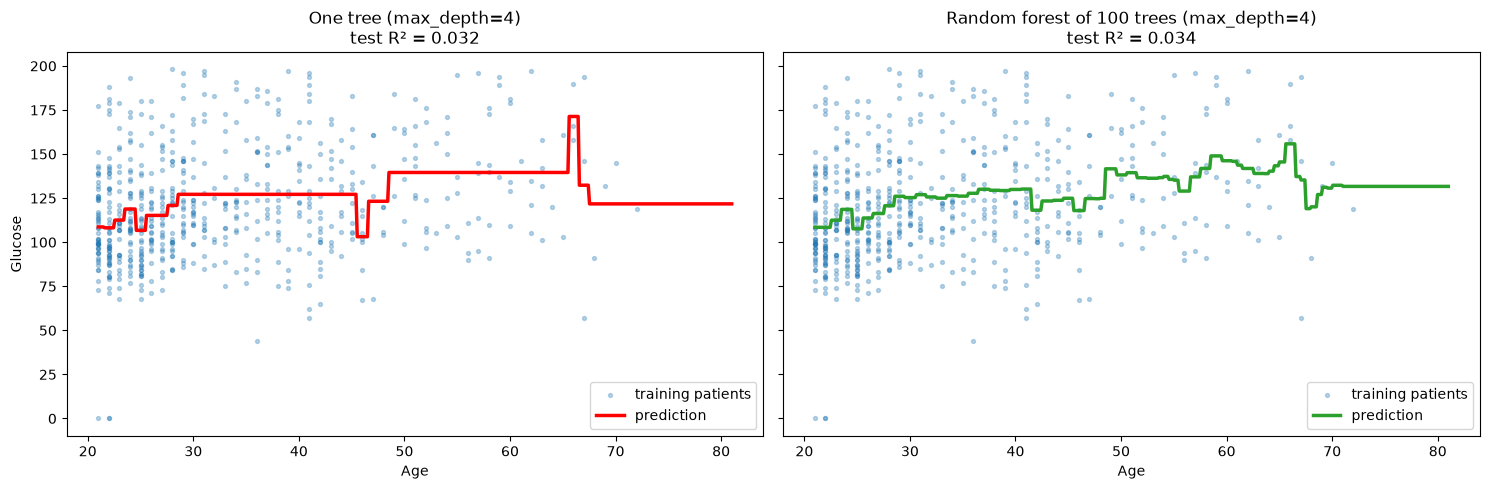

In [31]:
from sklearn.ensemble import RandomForestRegressor

age_tree4 = DecisionTreeRegressor(max_depth=4, random_state=1).fit(X_train[['Age']], y_train)
age_forest = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=1).fit(X_train[['Age']], y_train)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (name, m, color) in zip(axes, [('One tree (max_depth=4)', age_tree4, 'red'),
                                      ('Random forest of 100 trees (max_depth=4)', age_forest, 'tab:green')]):
    ax.scatter(X_train['Age'], y_train, s=8, alpha=0.3, color='tab:blue', label='training patients')
    ax.plot(age_grid['Age'], m.predict(age_grid), color=color, linewidth=2.5, label='prediction')
    ax.set_title(f'{name}\ntest R² = {m.score(X_test[["Age"]], y_test):.3f}')
    ax.set_xlabel('Age')
    ax.legend(loc='lower right')
axes[0].set_ylabel('Glucose')
plt.tight_layout()
plt.show()

The single tree's staircase has a few big, sudden jumps. The forest averages 100 staircases whose steps are in slightly different places, so the big jumps are **smoothed out** into many small steps that follow the overall trend more gradually.

### Recap: the random forest recipe for regression

1. **Bootstrap:** each tree gets its own random sample of the rows, drawn with replacement.
2. **Random features (optional):** each question may only use a random few features. Off by default for `RandomForestRegressor`.
3. **Grow:** grow each tree deep.
4. **Average:** the forest's prediction is the average of all the trees' predictions.


## Part 3: Random Forest with scikit-learn

Now the original example. `RandomForestRegressor` does all four steps for us. The settings used here:

| Setting | Meaning |
|---|---|
| `random_state=1` | makes the randomness repeatable |
| `max_depth=10` | each tree can ask at most 10 questions in a row |
| `n_estimators` (not set, so the default is used) | the number of trees. The default is now **100**. (When this example was first written, the default was only 10.) |
| `max_features` (not set) | the default for regression is 1.0, meaning all features (Step 2 is off) |

In [32]:
from sklearn.ensemble import RandomForestRegressor

# instantiate model
model = RandomForestRegressor(random_state=1, max_depth=10)

# fit model
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

### Make predictions

`predict` returns one estimated glucose value per test patient: the average over the forest's 100 trees. There are 154 of them, so we look at the first 10.

In [33]:
# make estimations for the testing set
y_pred = model.predict(X_test)
y_pred[:10].round(1)

array([153.5, 103.2, 101.5, 116.3, 125.4, 115. , 121.8,  94.7, 114.9,
       126.3])

### How good are the predictions?

For a regressor, `model.score` returns **R²**. We also compute the MAE and compare both with the "always guess the average" baseline.

In [34]:
from sklearn import metrics
print(model.score(X_test, y_test))

0.2295932319634737


In [35]:
rf_r2 = metrics.r2_score(y_test, y_pred)
rf_mae = metrics.mean_absolute_error(y_test, y_pred)
print(f"Random forest:  R² = {rf_r2:.3f},  MAE = {rf_mae:.1f}")
print(f"Baseline:       R² = {baseline_r2:.3f},  MAE = {baseline_mae:.1f}")

Random forest:  R² = 0.230,  MAE = 21.4
Baseline:       R² = -0.003,  MAE = 25.6


**How to interpret this:** the forest should beat the baseline, but only by a little: R² is **small**. The forest explains only a modest part of why some patients have higher glucose than others. That matches what the scatter plots in Part 0 suggested: these features are only weakly related to glucose. A model can be correctly built and still not be very useful, and it is important to say so honestly.

### Predicted vs. actual

If the predictions were perfect, every dot below would sit on the dashed diagonal line.

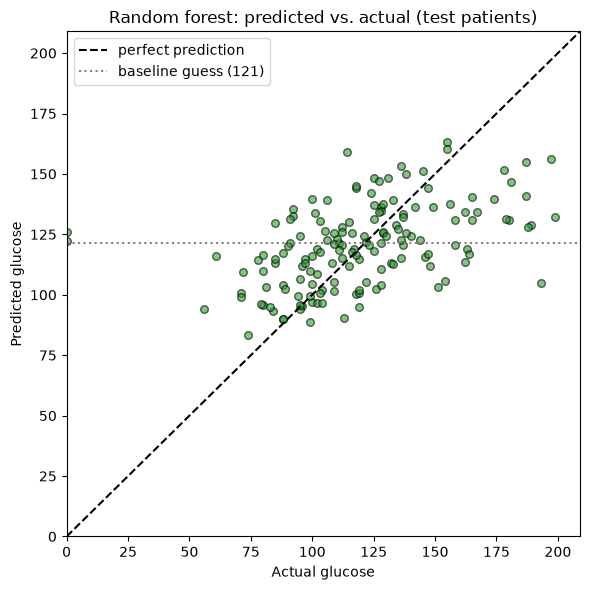

In [36]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, alpha=0.6, color='tab:green', edgecolor='k', s=30)
lims = [0, max(y_test.max(), y_pred.max()) + 10]
ax.plot(lims, lims, 'k--', label='perfect prediction')
ax.axhline(baseline_guess, color='gray', linestyle=':', label=f'baseline guess ({baseline_guess:.0f})')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('Actual glucose')
ax.set_ylabel('Predicted glucose')
ax.set_title('Random forest: predicted vs. actual (test patients)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Two things to notice:

1. The dots form a cloud that is **much flatter** than the diagonal line. Patients with very high actual glucose get predictions that are too low, and patients with low glucose get predictions that are too high. The predictions are pulled **toward the middle**. This happens because a forest predicts by **averaging**: when the features don't clearly point toward an extreme value, averages of averages end up near the overall average.
2. A random forest can **never predict a value outside the range of the training data**. Every prediction is an average of leaf values, and every leaf value is an average of real training patients.

The patients with a recorded glucose of 0 (the missing values) show up at the far left with large errors; no model could guess those.

### How big are the errors?

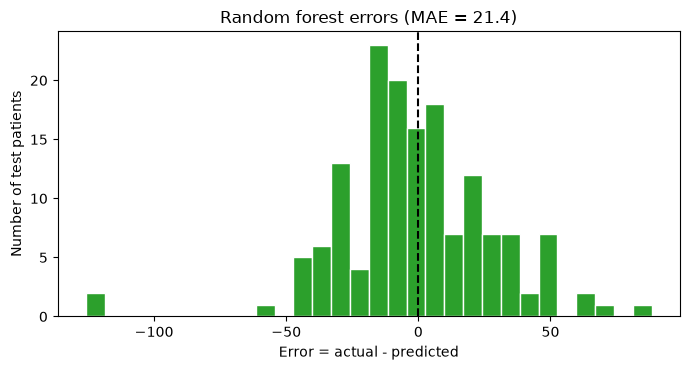

Half of the test patients have an error smaller than 16.7
The largest error is 125.8


In [37]:
errors = y_test - y_pred

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(errors, bins=30, color='tab:green', edgecolor='white')
ax.axvline(0, color='black', linestyle='--')
ax.set_xlabel('Error = actual - predicted')
ax.set_ylabel('Number of test patients')
ax.set_title(f'Random forest errors (MAE = {rf_mae:.1f})')
plt.tight_layout()
plt.show()

print(f"Half of the test patients have an error smaller than {np.median(np.abs(errors)):.1f}")
print(f"The largest error is {np.abs(errors).max():.1f}")

### Looking inside: the forest is a list of trees

As in Example 2, the forest's trees live in `model.estimators_`. The forest's prediction for a patient is **exactly** the average of its trees' predictions; let's check that for the first test patient.

Number of trees: 100
Lowest tree guess:  83.0
Highest tree guess: 196.0
Average of the 100 tree guesses: 153.46
Forest prediction (model.predict): 153.46
Actual glucose:                    136


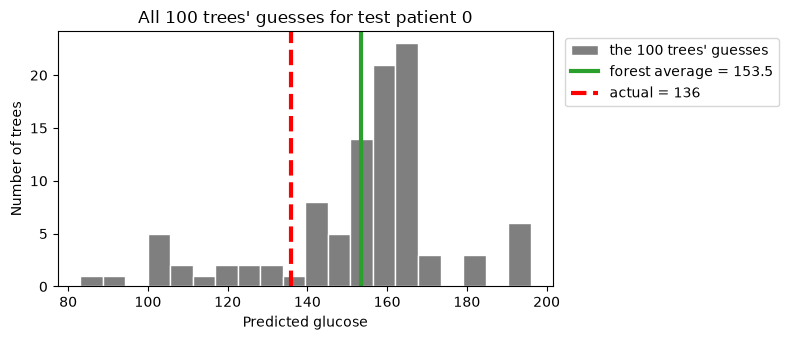

In [38]:
patient = X_test.iloc[[0]]
# .values because the trees inside the forest were trained without column names
tree_guesses = np.array([t.predict(patient.values)[0] for t in model.estimators_])

print("Number of trees:", len(model.estimators_))
print(f"Lowest tree guess:  {tree_guesses.min():.1f}")
print(f"Highest tree guess: {tree_guesses.max():.1f}")
print(f"Average of the 100 tree guesses: {tree_guesses.mean():.2f}")
print(f"Forest prediction (model.predict): {model.predict(patient)[0]:.2f}")
print(f"Actual glucose:                    {y_test.iloc[0]}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(tree_guesses, bins=20, color='tab:gray', edgecolor='white', label='the 100 trees\' guesses')
ax.axvline(tree_guesses.mean(), color='tab:green', linewidth=3, label=f'forest average = {tree_guesses.mean():.1f}')
ax.axvline(y_test.iloc[0], color='red', linewidth=3, linestyle='--', label=f'actual = {y_test.iloc[0]}')
ax.set_xlabel('Predicted glucose')
ax.set_ylabel('Number of trees')
ax.set_title('All 100 trees\' guesses for test patient 0')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### How many trees do we need?

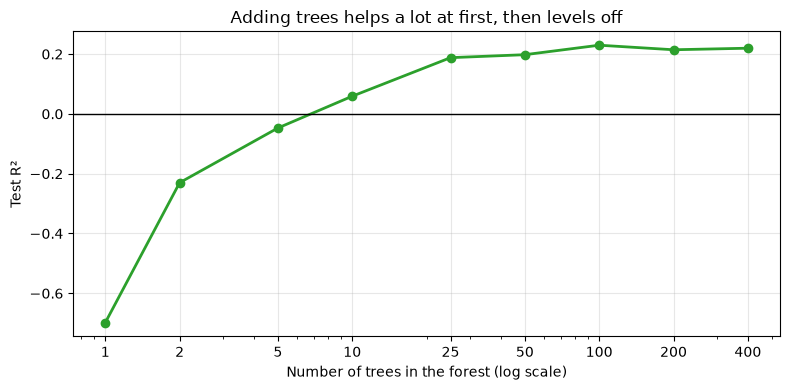

In [39]:
tree_counts = [1, 2, 5, 10, 25, 50, 100, 200, 400]
r2_by_count = [RandomForestRegressor(n_estimators=k, max_depth=10, random_state=1)
               .fit(X_train, y_train).score(X_test, y_test) for k in tree_counts]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tree_counts, r2_by_count, 'o-', color='tab:green', linewidth=2)
ax.axhline(0, color='black', linewidth=1)
ax.set_xscale('log')
ax.set_xticks(tree_counts)
ax.set_xticklabels(tree_counts)
ax.set_xlabel('Number of trees in the forest (log scale)')
ax.set_ylabel('Test R²')
ax.set_title('Adding trees helps a lot at first, then levels off')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

With only 1 or 2 trees, the "forest" is basically a single overfit tree, and R² is poor. As trees are added, their errors cancel more and more, and R² climbs before leveling off. This is why the change of the default from 10 to 100 trees was a good one.

### Out-of-bag score

Each tree never saw about 37% of the training patients (its **out-of-bag** patients). Scoring every training patient with only the trees that didn't see it gives an honest estimate of R² without using the test set.

In [40]:
model_oob = RandomForestRegressor(random_state=1, max_depth=10, oob_score=True).fit(X_train, y_train)
print(f"Out-of-bag R² estimate (training data only): {model_oob.oob_score_:.3f}")
print(f"R² on the real test set:                     {model_oob.score(X_test, y_test):.3f}")

Out-of-bag R² estimate (training data only): 0.197
R² on the real test set:                     0.230


### Which features matter most?

The original example prints and plots the forest's **feature importances**. For a regression forest, a feature's importance measures how much its questions reduced the squared error, added up over all the questions in all the trees, and scaled so that the importances add up to 1.

In [41]:
features = X.columns
print(features)
importances = model.feature_importances_
print(importances)

Index(['Pregnancies', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI',
       'DiabetesPedigreeFunction', 'Age'],
      dtype='str')
[0.06529962 0.09922355 0.10221913 0.26745643 0.14570905 0.14405487
 0.17603734]


The raw list is hard to read, so let's sort it and draw it as a bar chart. (The original version of this cell kept the "top 9" features, but there are only 7, so we simply sort and show them all.)

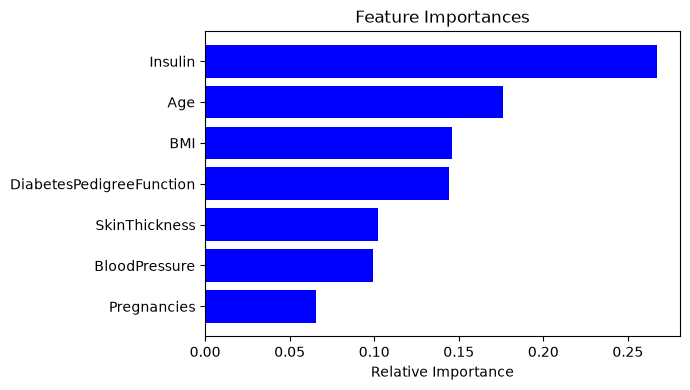

In [42]:
indices = np.argsort(importances)   # all features, from least to most important
plt.figure(figsize=(7, 4))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

### A second opinion: permutation importance

The importances above have a known weakness: they are computed on the **training** data, and they tend to favor features with many different values, even when those features don't actually help with new patients.

**Permutation importance** asks a more direct question: *if we scramble one feature's column in the **test** set, so it no longer matches the right patients, how much worse do the predictions get?* If scrambling a feature barely changes R², the model wasn't really relying on it. We repeat the scrambling 20 times per feature and show the average drop in R².

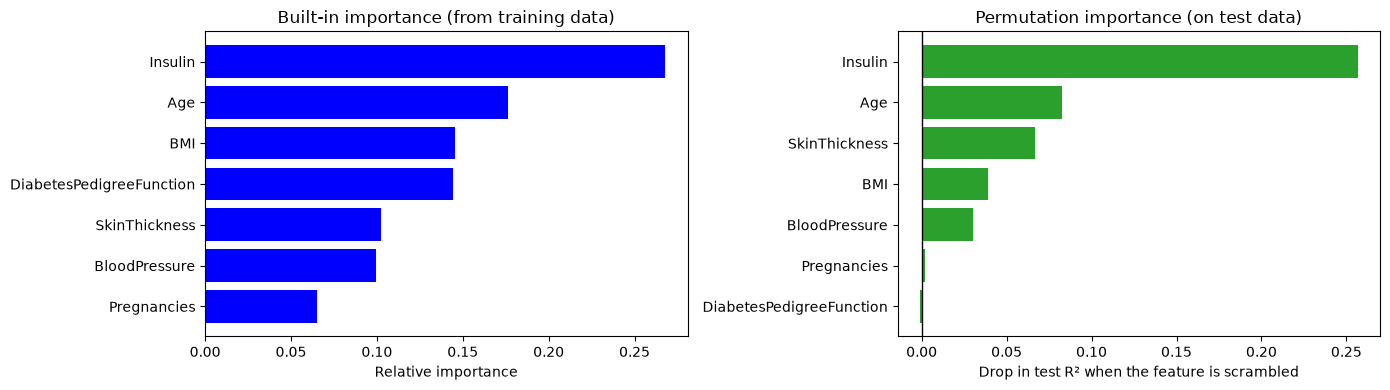

In [43]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, X_test, y_test, n_repeats=20, random_state=1)
perm_imp = pd.Series(perm.importances_mean, index=features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
imp = pd.Series(importances, index=features).sort_values()
axes[0].barh(imp.index, imp.values, color='b')
axes[0].set_title('Built-in importance (from training data)')
axes[0].set_xlabel('Relative importance')
axes[1].barh(perm_imp.index, perm_imp.values, color='tab:green')
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Permutation importance (on test data)')
axes[1].set_xlabel('Drop in test R² when the feature is scrambled')
plt.tight_layout()
plt.show()

Compare the two charts. Features near the top of **both** charts are the ones the forest genuinely relies on. A feature that looks important on the left but has a permutation importance near 0 (or even below 0) on the right is mostly helping the trees memorize the training data, not predict new patients.

As always, importance tells us what the model *uses*, not what *causes* high glucose. For example, insulin and glucose are both part of how the body handles sugar, so it makes sense that they are related, but this model cannot tell us which affects which.


## Part 4: Comparing the Models

### Scorecard

In [44]:
results = pd.DataFrame({
    'Model': ['Baseline (always guess the average)', 'Small tree (depth 2)', 'Single tree (depth 10)',
              'Hand-built forest (25 trees)', 'scikit-learn forest (100 trees)'],
    'Test R²': [baseline_r2,
                small_tree.score(X_test, y_test),
                metrics.r2_score(y_test, single_tree_pred),
                my_forest_r2,
                rf_r2],
    'Test MAE': [baseline_mae,
                 metrics.mean_absolute_error(y_test, small_tree.predict(X_test)),
                 metrics.mean_absolute_error(y_test, single_tree_pred),
                 metrics.mean_absolute_error(y_test, my_forest_pred),
                 rf_mae],
}).set_index('Model')
results.round(3)

,Test R²,Test MAE
Model,,
Baseline (always guess the average),-0.003,25.566
Small tree (depth 2),0.077,23.899
Single tree (depth 10),-0.133,26.240
Hand-built forest (25 trees),0.234,21.381
scikit-learn forest (100 trees),0.230,21.405


**How to read this table:**

* The **single depth-10 tree** is the fairest comparison for the forests, because the forests are made of exactly that kind of tree. Averaging should give the forests a much better R² than one such tree.
* The **small depth-2 tree** may do surprisingly well compared with the deep single tree, because it is too simple to memorize noise. Compare it with the forests too.
* All the R² values are small. With these seven features, even the best model can only explain a small part of the differences in glucose.

### Was this split typical? Repeat 30 times

With only 154 test patients, one split can be lucky or unlucky. Let's repeat the experiment with 30 different random splits. (This may take 30 seconds or so.)

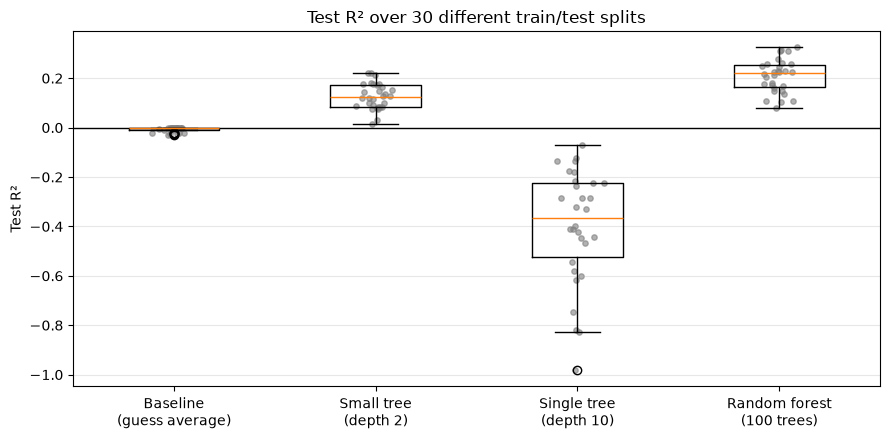

Baseline (guess average)     average R² = -0.007
Small tree (depth 2)         average R² = 0.126
Single tree (depth 10)       average R² = -0.398
Random forest (100 trees)    average R² = 0.209


In [45]:
model_makers = {
    'Baseline\n(guess average)': None,
    'Small tree\n(depth 2)': lambda: DecisionTreeRegressor(max_depth=2, random_state=1),
    'Single tree\n(depth 10)': lambda: DecisionTreeRegressor(max_depth=10, random_state=1),
    'Random forest\n(100 trees)': lambda: RandomForestRegressor(max_depth=10, random_state=1, n_jobs=-1),
}
repeat_r2 = {name: [] for name in model_makers}
for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=seed)
    for name, make in model_makers.items():
        if make is None:
            repeat_r2[name].append(metrics.r2_score(yte, np.full(len(yte), ytr.mean())))
        else:
            repeat_r2[name].append(make().fit(Xtr, ytr).score(Xte, yte))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(list(repeat_r2.values()))
ax.set_xticks(range(1, len(repeat_r2) + 1))
ax.set_xticklabels(list(repeat_r2.keys()))
for i, scores in enumerate(repeat_r2.values(), start=1):
    ax.scatter(np.random.default_rng(i).normal(i, 0.04, len(scores)), scores, color='tab:gray', alpha=0.6, s=15)
ax.axhline(0, color='black', linewidth=1)
ax.set_ylabel('Test R²')
ax.set_title('Test R² over 30 different train/test splits')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

for name, scores in repeat_r2.items():
    print(f"{name.replace(chr(10), ' '):<28} average R² = {np.mean(scores):.3f}")

Look at where each box sits relative to the R² = 0 line, and how spread out each box is. You should find that the single deep tree is the worst and least consistent model, while the forest, made of trees just like it, does much better: the same "wisdom of crowds" effect we saw in Part 2. Also compare the forest with the small depth-2 tree: on a problem this hard, a very simple model can be surprisingly competitive.

### Why is R² so low, and is that a failure?

Not at all; it is an honest result. Some reasons the problem is hard:

* **The features just don't contain much information about glucose.** Glucose depends on many things not in this dataset, such as diet, what the patient ate that day, medications, and genetics beyond the pedigree score.
* **Missing values recorded as 0.** Half of the `Insulin` values and a few `Glucose` values are really missing, which adds noise to both the inputs and the target.
* **A small dataset.** 614 training patients is not many for learning a complicated relationship.

A good data scientist reports a weak result as weak, explains why, and suggests what might help (better data, more features, cleaning the missing values) instead of hiding it.

---
## Summary

**Regression vs. classification**

* Regression predicts a **number**; classification predicts a **category**.
* A **regression tree** works like a classification tree, but its leaves predict the **average** of the training values in the leaf, and it chooses questions that make each group's values as **similar** as possible (lowest mean squared error).
* A regression tree's prediction is a **staircase**: flat within each leaf and jumping at each cut-off.

**Random forest for regression**

* Same recipe as before: bootstrap samples, (optionally) random features, deep trees.
* The final prediction is the **average** of the trees' predictions instead of a vote.
* Individual deep trees overfit and can be worse than guessing the average, but their average is much better, because their errors cancel out.
* Averaging also **smooths** the staircase and pulls predictions **toward the middle**; a forest can't predict outside the range of the training data.

**Measuring regression models**

* **MAE**: the average size of the error, in the same units as the target.
* **R²**: how much better than always guessing the average (1 = perfect, 0 = no better, below 0 = worse).
* Always compare against a simple **baseline**.

**Vocabulary:** regression, residual/error, MAE, R², baseline, mean squared error, regression tree, staircase prediction, overfitting, bootstrap, bagging, averaging, out-of-bag, feature importance, permutation importance.

